In [1]:
import pandas as pd
import os

os.chdir("Z:\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")

# Load the dataset
df = pd.read_csv('global_power_plant_database.csv')

# Filter for Spain and renewable energy sources
df_spain = df[(df['country'] == 'ESP') & (df['primary_fuel'].isin(['Wind', 'Solar']))]

# Display the filtered data
print(df_spain[['name', 'primary_fuel', 'capacity_mw', 'latitude', 'longitude']])


                       name primary_fuel  capacity_mw  latitude  longitude
20138                AGREDA         Wind        18.00   41.8559    -1.9224
20145            ALENTISQUE         Wind        46.50   41.4206    -2.3319
20146     ALTO DE LA SIERRA         Wind        11.05   41.5406    -1.7166
20148  AMPLIACION DEL PICAL         Wind        11.05   42.9362    -4.3083
20149  AMPLIACION PADORNELO         Wind        18.00   42.0357    -6.9054
...                     ...          ...          ...       ...        ...
20959               Zaratán        Solar         9.00   41.6428    -4.8151
20960                 Zarza        Solar         7.60   39.8710    -6.8320
20961               Zuera I        Solar         9.00   41.9340    -0.8050
20962              Zuera II        Solar         9.90   41.9440    -0.8180
20963                 Zújar        Solar         7.00   38.9420    -5.8750

[585 rows x 5 columns]


C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_15312\2464871789.py:7: DtypeWarning: Columns (10,17,18,26,27,37,38) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('global_power_plant_database.csv')


In [2]:
# Filter for Spain and renewable energy sources
df_wind_spain = df[(df['country'] == 'ESP') & (df['primary_fuel'].isin(['Wind'])) & (df['longitude'] < 10)]
df_wind_spain

,country,country_long,name,gppd_idnr,capacity_mw,latitude,longitude,primary_fuel,other_fuel1,other_fuel2,...,estimated_generation_gwh_2016,estimated_generation_gwh_2017,estimated_generation_note_2013,estimated_generation_note_2014,estimated_generation_note_2015,estimated_generation_note_2016,estimated_generation_note_2017,Unnamed: 36,Unnamed: 37,Unnamed: 38
20138,ESP,Spain,AGREDA,WRI1006162,18.00,41.8559,-1.9224,Wind,NaN,NaN,...,51.20,50.55,NO-ESTIMATION,WIND-V1,WIND-V1,WIND-V1,WIND-V1,NaN,NaN,NaN
20145,ESP,Spain,ALENTISQUE,WRI1006179,46.50,41.4206,-2.3319,Wind,NaN,NaN,...,119.89,117.78,WIND-V1,WIND-V1,WIND-V1,WIND-V1,WIND-V1,NaN,NaN,NaN
20146,ESP,Spain,ALTO DE LA SIERRA,WRI1006185,11.05,41.5406,-1.7166,Wind,NaN,NaN,...,NaN,23.50,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,CAPACITY-FACTOR-V1,NaN,NaN,NaN
20148,ESP,Spain,AMPLIACION DEL PICAL,WRI1006191,11.05,42.9362,-4.3083,Wind,NaN,NaN,...,NaN,23.50,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,CAPACITY-FACTOR-V1,NaN,NaN,NaN
20149,ESP,Spain,AMPLIACION PADORNELO,WRI1006192,18.00,42.0357,-6.9054,Wind,NaN,NaN,...,43.73,43.80,WIND-V1,WIND-V1,WIND-V1,WIND-V1,WIND-V1,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20874,ESP,Spain,SERRA DE RUBIO,WRI1007897,75.00,41.6485,1.5914,Wind,NaN,NaN,...,211.82,194.42,WIND-V1,WIND-V1,WIND-V1,WIND-V1,WIND-V1,NaN,NaN,NaN
20875,ESP,Spain,SERRA DE VILOBI,WRI1007900,40.50,42.1555,2.2828,Wind,NaN,NaN,...,108.59,102.13,WIND-V1,WIND-V1,WIND-V1,WIND-V1,WIND-V1,NaN,NaN,NaN
20876,ESP,Spain,SERRA DEL TALLAT,WRI1007901,49.50,42.3833,2.2667,Wind,NaN,NaN,...,131.29,119.51,WIND-V1,WIND-V1,WIND-V1,WIND-V1,WIND-V1,NaN,NaN,NaN
20877,ESP,Spain,SIERRA DE LA VIRGEN,WRI1007912,24.42,41.5406,-1.7166,Wind,NaN,NaN,...,NaN,51.93,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,CAPACITY-FACTOR-V1,NaN,NaN,NaN


In [3]:
from sklearn.cluster import KMeans
import numpy as np
import matplotlib as mpl

# Préparer les coordonnées (latitude, longitude)
coords = df_wind_spain[['latitude', 'longitude']].values

# Appliquer KMeans avec 50 clusters
kmeans = KMeans(n_clusters=50, random_state=0)
df_wind_spain['group'] = kmeans.fit_predict(coords)

# Vérifier que ça fait bien 50 groupes (300/6 = 50)
print("Nombre de groupes:", df_wind_spain['group'].nunique())

# Fonction pour calculer barycentre pondéré par capacity_mw
def weighted_centroid(group):
    weights = group['capacity_mw']
    lat = np.average(group['latitude'], weights=weights)
    lon = np.average(group['longitude'], weights=weights)
    total_capacity = weights.sum()
    return pd.Series({'latitude': lat, 'longitude': lon, 'total_capacity_mw': total_capacity})

# Appliquer la fonction par groupe
df_grouped = df_wind_spain.groupby('group').apply(weighted_centroid).reset_index(drop=True)

print(df_grouped.head())

Nombre de groupes: 50
    latitude  longitude  total_capacity_mw
0  42.282151  -7.606360             293.06
1  39.462994  -2.071221             713.20
2  36.205973  -5.742925             397.53
3  41.524392  -1.066542             669.09
4  40.548457  -4.447393             148.58


C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_15312\3162073390.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_wind_spain['group'] = kmeans.fit_predict(coords)
C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_15312\3162073390.py:24: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_grouped = df_wind_spain.groupby('group').apply(weighted_centroid).reset_index(drop=True)


C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_15312\2206416948.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_wind_spain[estimated_gen_cols] = df_wind_spain[estimated_gen_cols].apply(
C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_15312\2206416948.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_wind_spain["generation_gwh_avg"] = df_wind_spain[estimated_gen_cols].mean(axis=1, skipna=True)
C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_15312\2206416948.py:13: SettingWithCopyWarning: 
A value is try

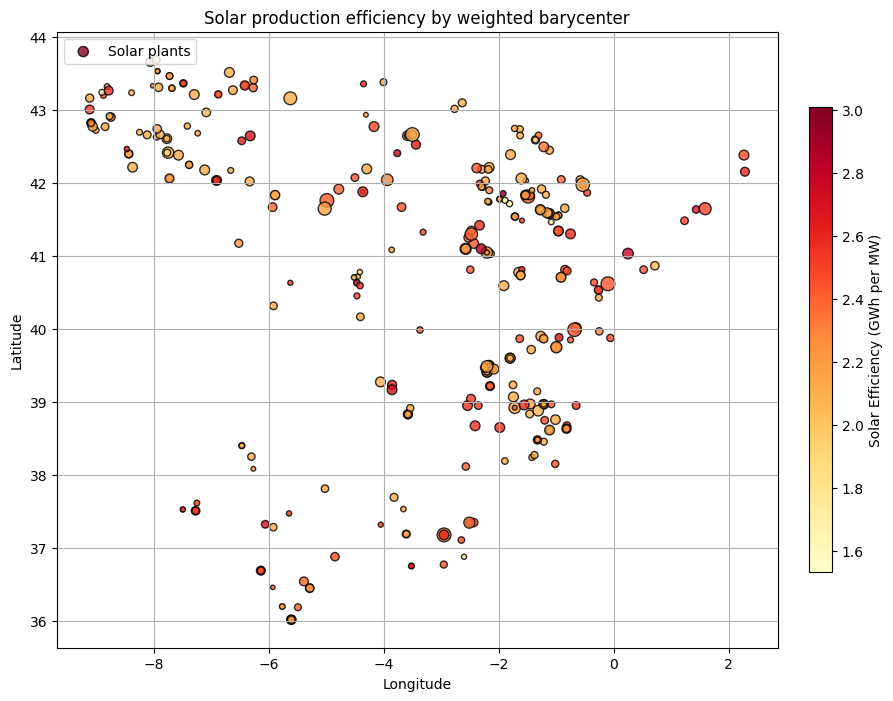

In [4]:
import matplotlib.pyplot as plt

# Identifier automatiquement les colonnes de génération
estimated_gen_cols = [c for c in df_wind_spain.columns if c.startswith("estimated_generation_gwh_")]
# Calculer la moyenne row-wise en ignorant les NA
df_wind_spain[estimated_gen_cols] = df_wind_spain[estimated_gen_cols].apply(
    pd.to_numeric, errors='coerce'
)

df_wind_spain["generation_gwh_avg"] = df_wind_spain[estimated_gen_cols].mean(axis=1, skipna=True)

# Vérification
df_wind_spain["efficiency"] = df_wind_spain["generation_gwh_avg"] / df_wind_spain["capacity_mw"] 

# Normaliser les valeurs d'efficiency
vmin = df_wind_spain["efficiency"].min()
vmax = df_wind_spain["efficiency"].max()

# Choisir une colormap continue
cmap = plt.cm.YlOrRd

# Facteur de taille (à ajuster si nécessaire)
size_factor = 1   # multiplier pour ajuster visuellement

# Création de la figure
fig, ax = plt.subplots(figsize=(10, 8))

# Scatter : couleur = efficiency, taille = capacity_mw
sc = ax.scatter(
    df_wind_spain['longitude'],
    df_wind_spain['latitude'],
    c=df_wind_spain['efficiency'],
    cmap=cmap,
    s=df_wind_spain['capacity_mw'] * size_factor,   # ← ajout clé
    edgecolor='black',
    alpha=0.8,
    label='Solar plants'
)

# Titre + axes
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Solar production efficiency by weighted barycenter")

# Légende standard pour les types de points
ax.legend(loc="upper left")

# Barre de couleur continue
cbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax), cmap=cmap),
    ax=ax,
    fraction=0.03,
    pad=0.04
)
cbar.set_label("Solar Efficiency (GWh per MW)")

plt.grid(True)
plt.show()




mettre en évidence le fait qu'il est plus logique de pondérer par l'énergie moyenne à cause des différences d'efficacité

C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_15312\1629839190.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_solar_spain[estimated_gen_cols] = df_solar_spain[estimated_gen_cols].apply(
C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_15312\1629839190.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_solar_spain["generation_gwh_avg"] = df_solar_spain[estimated_gen_cols].mean(axis=1, skipna=True)
C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_15312\1629839190.py:18: SettingWithCopyWarning: 
A value i

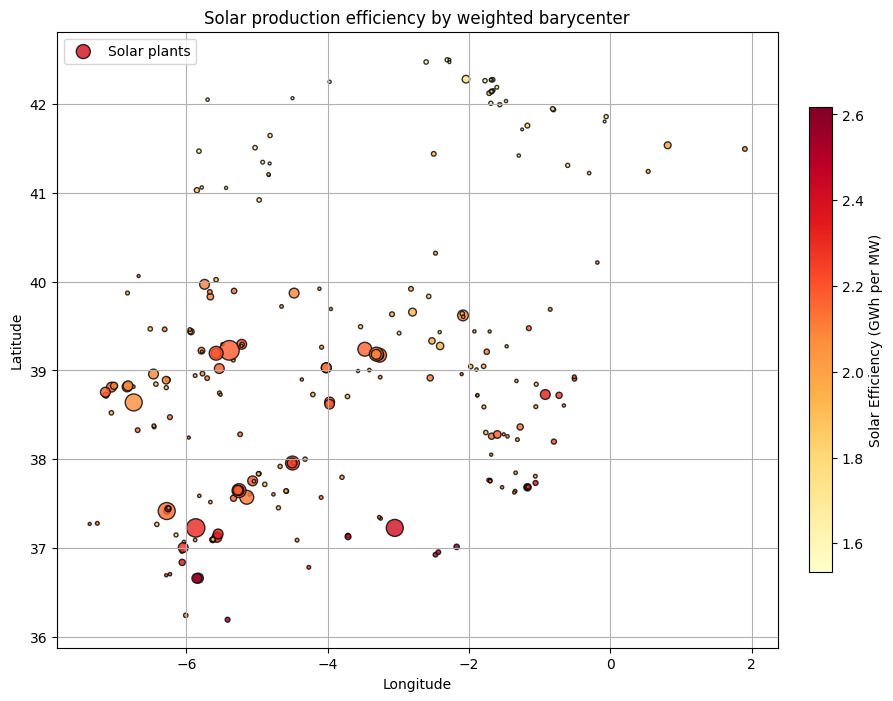

In [5]:
import matplotlib.pyplot as plt


# Filter for Spain and renewable energy sources
df_solar_spain = df[(df['country'] == 'ESP') & (df['primary_fuel'].isin(['Solar'])) & (df['longitude'] < 10)& (df['longitude'] > -15)]
coords = df_solar_spain[['latitude', 'longitude']].values

# Identifier automatiquement les colonnes de génération
estimated_gen_cols = [c for c in df_solar_spain.columns if c.startswith("estimated_generation_gwh_")]
# Calculer la moyenne row-wise en ignorant les NA
df_solar_spain[estimated_gen_cols] = df_solar_spain[estimated_gen_cols].apply(
    pd.to_numeric, errors='coerce'
)

df_solar_spain["generation_gwh_avg"] = df_solar_spain[estimated_gen_cols].mean(axis=1, skipna=True)

# Vérification
df_solar_spain["efficiency"] = df_solar_spain["generation_gwh_avg"] / df_solar_spain["capacity_mw"] 



# Normaliser les valeurs d'efficiency
vmin = df_solar_spain["efficiency"].min()
vmax = df_solar_spain["efficiency"].max()

# Choisir une colormap continue
cmap = plt.cm.YlOrRd

# Facteur de taille (à ajuster si nécessaire)
size_factor = 1   # multiplier pour ajuster visuellement

# Création de la figure
fig, ax = plt.subplots(figsize=(10, 8))

# Scatter : couleur = efficiency, taille = capacity_mw
sc = ax.scatter(
    df_solar_spain['longitude'],
    df_solar_spain['latitude'],
    c=df_solar_spain['efficiency'],
    cmap=cmap,
    s=df_solar_spain['capacity_mw'] * size_factor,   # ← ajout clé
    edgecolor='black',
    alpha=0.8,
    label='Solar plants'
)

# Titre + axes
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Solar production efficiency by weighted barycenter")

# Légende standard pour les types de points
ax.legend(loc="upper left")

# Barre de couleur continue
cbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax), cmap=cmap),
    ax=ax,
    fraction=0.03,
    pad=0.04
)
cbar.set_label("Solar Efficiency (GWh per MW)")

plt.grid(True)
plt.show()


On regarde si le fait de considérer la construction progressive du parc nous aide

In [6]:
# Pivot longer
df_long = df_solar_spain.melt(
    id_vars=["capacity_mw"  ,"latitude", "longitude",
			 'generation_gwh_avg', 'commissioning_year', 'efficiency'],
    value_vars=estimated_gen_cols,
    var_name='year',
    value_name='generation_gwh'
)

# Nettoyer la colonne year (enlever "generation_gwh_")
df_long["year"] = df_long["year"].str.replace("estimated_generation_gwh_", "").astype(int)

print(df_long.head())

   capacity_mw  latitude  longitude  generation_gwh_avg  commissioning_year  \
0        149.7   37.2281    -3.0511             360.776              2011.0   
1         99.8   39.1710    -3.2666             215.554              2012.0   
2         49.9   38.8120    -7.0587             108.286              2012.0   
3          5.2   38.8980    -4.3660              10.564                 NaN   
4         23.0   39.2226    -5.7853              47.870                 NaN   

   efficiency  year  generation_gwh  
0    2.409993  2013          388.84  
1    2.159860  2013          210.94  
2    2.170060  2013          111.79  
3    2.031538  2013           10.42  
4    2.081304  2013           49.02  


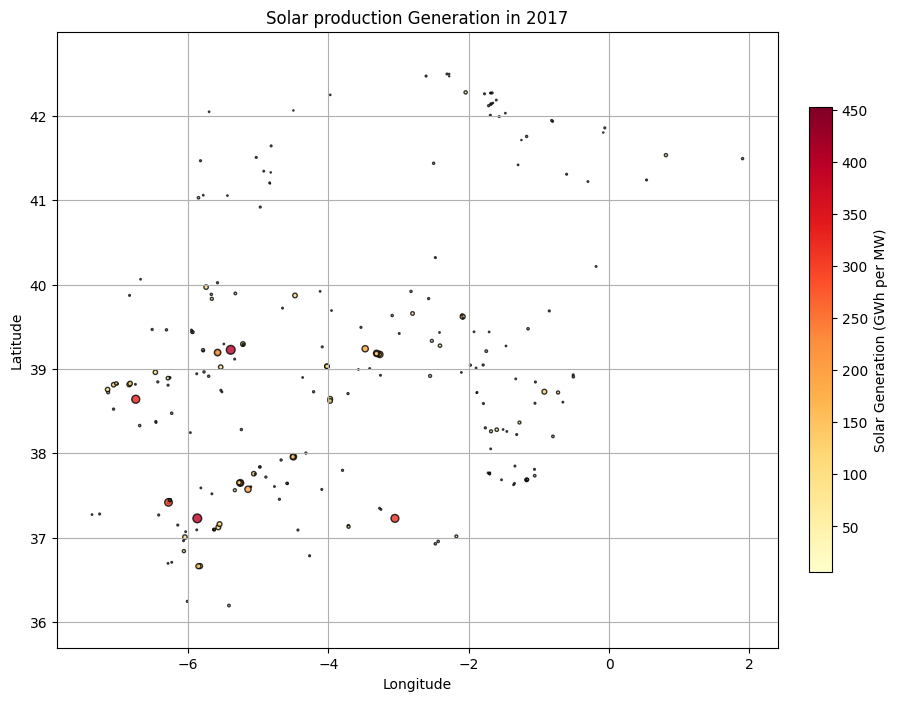

In [7]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.animation import FuncAnimation
import numpy as np

# Préparer les années uniques
years = sorted(df_long['year'].dropna().unique())

# Colormap
cmap = plt.cm.YlOrRd
vmin = df_long["generation_gwh"].min()
vmax = df_long["generation_gwh"].max()

# Figure
fig, ax = plt.subplots(figsize=(10, 8))
sc = ax.scatter([], [], c=[], cmap=cmap, s=[], edgecolor='black', alpha=0.8)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Solar production Generation by year")

cbar = fig.colorbar(mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax), cmap=cmap),
                    ax=ax, fraction=0.03, pad=0.04)
cbar.set_label("Solar Generation (GWh per MW)")

ax.set_xlim(df_long['longitude'].min()-0.5, df_long['longitude'].max()+0.5)
ax.set_ylim(df_long['latitude'].min()-0.5, df_long['latitude'].max()+0.5)
ax.grid(True)

# Fonction d'update
def update(year):
    ax.set_title(f"Solar production Generation in {year}")
    df_year = df_long[df_long['year'] == year]
    sc.set_offsets(np.c_[df_year['longitude'], df_year['latitude']])
    sc.set_array(df_year['generation_gwh'])
    sc.set_sizes(df_year['generation_gwh']*0.1)  # facteur de taille
    return sc,

# Animation
ani = FuncAnimation(fig, update, frames=years, interval=1000, blit=False)

# Pour sauvegarder en GIF
ani.save("solar_efficiency_animation.gif", writer='pillow', dpi=150)

plt.show()


In [8]:
from IPython.display import HTML
HTML(ani.to_jshtml())

C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_15312\1234323190.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_solar_spain['generation_gwh_avg'] = pd.to_numeric(df_solar_spain['generation_gwh_avg'], errors='coerce')
C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_15312\1234323190.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_solar_spain['group'] = kmeans.fit_predict(coords, sample_weight=weights)
C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_15312\1234323190.py:18: DeprecationWarning: DataFrameG

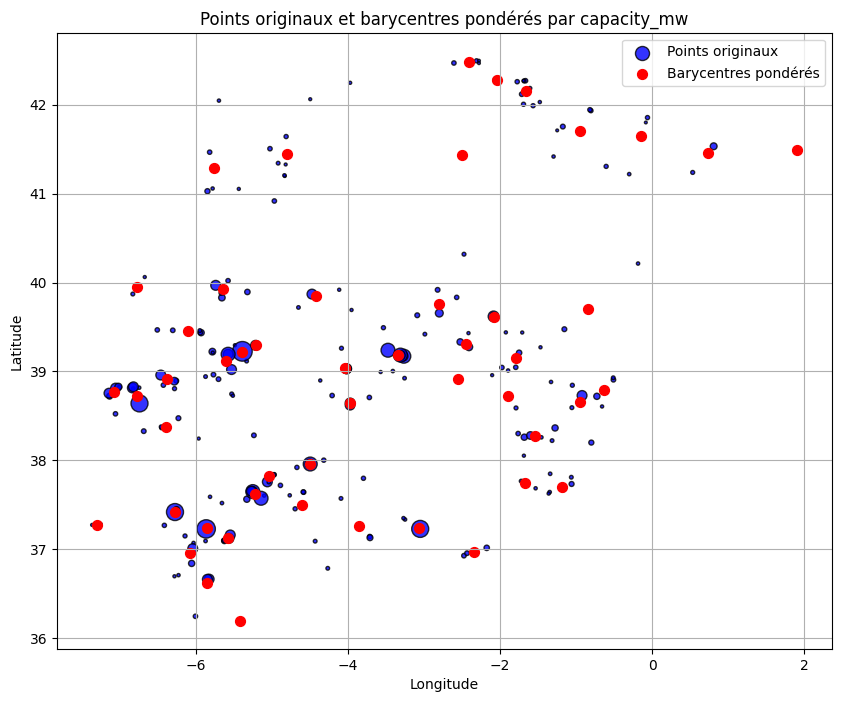

In [9]:
from sklearn.cluster import KMeans
import numpy as np

# Vérifier que generation_gwh_avg est numérique
df_solar_spain['generation_gwh_avg'] = pd.to_numeric(df_solar_spain['generation_gwh_avg'], errors='coerce')

# Remplacer NA weights par petite valeur
weights = df_solar_spain['generation_gwh_avg'].fillna(0.0001).values

# ⚠️ KMeans pondéré
kmeans = KMeans(
    n_clusters=50,
    random_state=0
)
df_solar_spain['group'] = kmeans.fit_predict(coords, sample_weight=weights)

# Calcul des barycentres pondérés
df_grouped_solar = df_solar_spain.groupby('group').apply(weighted_centroid).reset_index(drop=True)
# Création de la figure
fig, ax = plt.subplots(figsize=(10, 8))

# Points originaux
sc = ax.scatter(
    df_solar_spain['longitude'],
    df_solar_spain['latitude'], 
	c='blue',
    s=df_solar_spain['capacity_mw'] * size_factor,   # ← ajout clé
    edgecolor='black',
    alpha=0.8,
    label='Points originaux'
)
#plt.scatter(df_solar_spain['longitude'], df_solar_spain['latitude'], c='blue', s=10, label='Points originaux', alpha=0.6)
# Barycentres pondérés
plt.scatter(df_grouped_solar['longitude'], df_grouped_solar['latitude'], c='red', s=50, label='Barycentres pondérés')

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Points originaux et barycentres pondérés par capacity_mw')
plt.legend()
plt.grid(True)
plt.show()

Le problème de cette technique c'est que certains points comme barycentres ne sont proches de personne

In [10]:
# Trier par capacité décroissante
df_sorted = df_wind_spain.sort_values("generation_gwh_avg", ascending=False)

# Capacité totale
total_capacity = df_sorted["generation_gwh_avg"].sum()

# Capacité cumulée
df_sorted["cum_capacity"] = df_sorted["generation_gwh_avg"].cumsum()

# Trouver la ligne où on dépasse 80%
threshold_row = df_sorted[df_sorted["cum_capacity"] >= 0.8 * total_capacity].iloc[0]

threshold_wind = threshold_row["generation_gwh_avg"]

print("Seuil éolien à partir duquel on garde 80% de la capacité :", threshold_wind)

df_wind_spain_big = df_wind_spain[df_wind_spain['generation_gwh_avg'] > threshold_wind ]
print(f"Nombre de points à télécharger : {len(df_wind_spain_big)} contre {len(df_wind_spain)} au total")



# Trier par capacité décroissante
df_sorted = df_solar_spain.sort_values("generation_gwh_avg", ascending=False)

# Capacité totale
total_capacity = df_sorted["generation_gwh_avg"].sum()

# Capacité cumulée
df_sorted["cum_capacity"] = df_sorted["generation_gwh_avg"].cumsum()

# Trouver la ligne où on dépasse 80%
threshold_row = df_sorted[df_sorted["cum_capacity"] >= 0.8 * total_capacity].iloc[0]

threshold_wind = threshold_row["generation_gwh_avg"]

print("Seuil solaire à partir duquel on garde 80% de la capacité :", threshold_wind)

df_solar_spain_big = df_solar_spain[df_solar_spain['generation_gwh_avg'] > threshold_wind ]
print(f"Nombre de points à télécharger : {len(df_solar_spain_big)} contre {len(df_solar_spain)} au total")

# df_solar_spain_big = df_solar_spain[df_solar_spain['generation_gwh_avg'] > 50]
# print(f"Nombre de points à télécharger : {len(df_solar_spain_big)}")



Seuil éolien à partir duquel on garde 80% de la capacité : 55.82
Nombre de points à télécharger : 211 contre 340 au total
Seuil solaire à partir duquel on garde 80% de la capacité : 22.112000000000002
Nombre de points à télécharger : 86 contre 235 au total


Show spatially unequal distribution of production and consumption across the Spanish territory

Index(['longitude', 'latitude', 'geometry', 'index_right', 'comunidad',
       'centroid', 'lon', 'lat', 'comunidad_shapefile', 'conso_elec',
       'factor'],
      dtype='object')


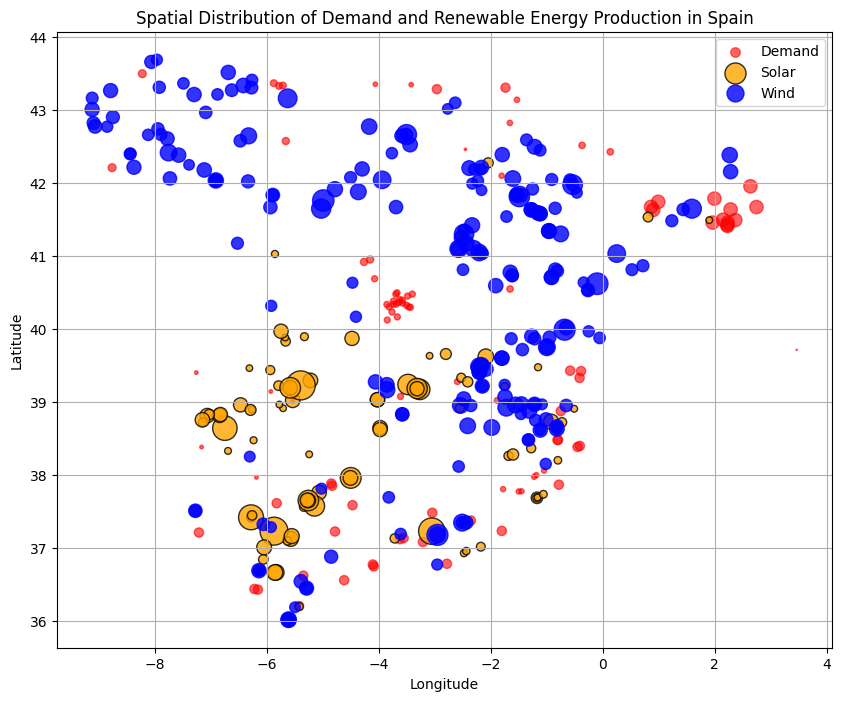

In [11]:
os.chdir(r"C:/Users/DBT3KD/Desktop/Etude_macro_elec/prix_electricite_gitlab\day_ahead\daily_temp\outputs")
gdf_demand_points = pd.read_csv("demand_points_corrected.csv")
print(gdf_demand_points.columns)

# Création de la figure
fig, ax = plt.subplots(figsize=(10, 8))
# Définir un facteur pour la taille
size_factor = 0.00005
# Set the output path
output_path = r"C:/Users/DBT3KD/Desktop/Etude_macro_elec/Overleaf_elec\images\data_description"

# Ensure folder exists (optional)
os.makedirs(output_path, exist_ok=True)

# Build full filename
savefile = os.path.join(output_path, "spain_demand_solar_wind_map.png")


# Points de demande
plt.scatter(
    gdf_demand_points['longitude'],
    gdf_demand_points['latitude'],
    c='red',
    s=gdf_demand_points['conso_elec'].values * size_factor,
    alpha=0.6,
    label='Demand'
)


# Points solaire
sc = ax.scatter(
    df_solar_spain_big['longitude'],
    df_solar_spain_big['latitude'], 
	 c='orange',
    s=df_solar_spain_big['generation_gwh_avg'],   # ← ajout clé
    edgecolor='black',
    alpha=0.8,
    label='Solar'
)

# Points éolien
plt.scatter(
    df_wind_spain_big['longitude'],
    df_wind_spain_big['latitude'],
    c='blue',
    s=df_wind_spain_big['generation_gwh_avg'],
    alpha=0.8,
    label='Wind'
)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Spatial Distribution of Demand and Renewable Energy Production in Spain')
plt.legend()
plt.grid(True)
# 🟢 SAVE THE FIGURE
plt.savefig(savefile, dpi=300, bbox_inches='tight')
plt.show()

In [12]:
# Ajouter une colonne 'source' à chaque dataframe
df_grouped['source'] = 'wind'
df_grouped_solar['source'] = 'solar'

# Concaténer
df_wind_solar_spain = pd.concat([df_grouped, df_grouped_solar], ignore_index=True)

df_wind_solar_spain.to_csv('df_wind_solar_spain.csv', index=False) 

In [13]:
df_wind_solar_spain

,latitude,longitude,total_capacity_mw,source
0,42.282151,-7.606360,293.06,wind
1,39.462994,-2.071221,713.20,wind
2,36.205973,-5.742925,397.53,wind
3,41.524392,-1.066542,669.09,wind
4,40.548457,-4.447393,148.58,wind
...,...,...,...,...
95,39.944935,-6.771226,12.40,solar
96,39.151665,-1.786939,50.70,solar
97,36.195000,-5.416000,12.30,solar
98,39.312125,-2.455132,54.40,solar


In [15]:
import openmeteo_requests
import pandas as pd
import requests_cache
from retry_requests import retry
import time
import os
os.chdir("C:\\Users\\DBT3KD\\Downloads")

# Configuration Open-Meteo
cache_session = requests_cache.CachedSession('.cache', expire_after=-1)
retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
openmeteo = openmeteo_requests.Client(session=retry_session)

# Période d'intérêt
start_date = "2015-01-01"
end_date = "2023-12-31"


Je voudrais réduire le nombre de points à télécharger tout en gardant une bonne couverture typiquement 80 à 90 % de l'énergie totale produite par éolienne et solaire

In [23]:
# cache_session = requests_cache.CachedSession('.cache', expire_after=-1)
# retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
print(cache_session.proxies)
print(retry_session.proxies)
#openmeteo = openmeteo_requests.Client(session=retry_session)

{}
{}


In [34]:
import requests

session = requests.Session()
session.proxies = {
    "http": "http://proxy-rie.http.insee.fr:3128",
    "https": "https://proxy-rie.https.insee.fr:3128"
}
# session.proxies = {
#     "http": "http://10.10.1.10:3128",
#     "https": "http://10.10.1.10:1080",
# }
openmeteo = openmeteo_requests.Client(session=session)

In [16]:
import os
import time
import pandas as pd
import openmeteo_requests

# --- PARAMÈTRES ---
BATCH_SIZE = 10
OUTPUT_DIR = r"C:/Users/DBT3KD/Desktop/Etude_macro_elec/prix_electricite_gitlab\day_ahead\daily_temp\outputs\wind_batches"
os.makedirs(OUTPUT_DIR, exist_ok=True)

#http://proxy-rie.http.insee.fr:8080

def download_wind_sun_batched(df, prefix="wind", start_batch=1):
    all_batches = []

    # Découper en batchs
    batches = [df.iloc[i:i+BATCH_SIZE] for i in range(0, len(df), BATCH_SIZE)]
    total_batches = len(batches)

    for b_idx, batch_df in enumerate(batches, start=1):

        # ⛔ Sauter les batchs déjà faits
        if b_idx < start_batch:
            print(f"⏭️  Batch {b_idx} déjà traité — on saute.")
            continue

        print(f"\n🔵 --- Batch {b_idx}/{total_batches} : {len(batch_df)} points ---")

        batch_results = []

        for idx, row in batch_df.iterrows():
            lat = row["latitude"]
            lon = row["longitude"]

            params = {
                "latitude": lat,
                "longitude": lon,
                "start_date": start_date,
                "end_date": end_date,
                #"hourly": ["wind_speed_100m", "cloud_cover", "global_tilted_irradiance"]
                "hourly": ["temperature_2m", "relative_humidity_2m", "precipitation"]
            }

            success = False
            while not success:
                try:
                    responses = openmeteo.weather_api(
                        "https://archive-api.open-meteo.com/v1/archive",
                        params=params
                    )
                    response = responses[0]
                    hourly = response.Hourly()

                    time_index = pd.date_range(
                        start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                        end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                        freq=pd.Timedelta(seconds=hourly.Interval()),
                        inclusive="left"
                    )

                    # data = {
                    #     "latitude": lat,
                    #     "longitude": lon,
                    #     "date": time_index,
                    #     "wind_speed_100m": hourly.Variables(0).ValuesAsNumpy(),
                    #     "cloud_cover": hourly.Variables(1).ValuesAsNumpy(),
                    #     "global_tilted_irradiance": hourly.Variables(2).ValuesAsNumpy()
                    # }

                    data = {
					"latitude": lat,
					"longitude": lon,
					"date": time_index,
					"temperature_2m": hourly.Variables(0).ValuesAsNumpy(),
					"relative_humidity_2m": hourly.Variables(1).ValuesAsNumpy(),
					"precipitation": hourly.Variables(2).ValuesAsNumpy()
				    }   

                    df_point = pd.DataFrame(data)
                    batch_results.append(df_point)

                    print(f"   ✅ Point OK ({lat}, {lon})")

                    time.sleep(3)
                    success = True

                except Exception as e:
                    if "request limit exceeded" in str(e).lower():
                        print("   ⏳ Limite API atteinte → pause 60 sec...")
                        time.sleep(60)
                    else:
                        print(f"   ⚠️ Échec pour ({lat}, {lon}) : {e}")
                        success = True  # éviter boucle infinie

        # --- Sauvegarde du batch ---
        if batch_results:
            df_batch = pd.concat(batch_results, ignore_index=True)
            batch_file = os.path.join(OUTPUT_DIR, f"{prefix}_batch_{b_idx:02d}.parquet")
            df_batch.to_parquet(batch_file, index=False)

            print(f"💾 Batch {b_idx}/{total_batches} sauvegardé : {batch_file}")

            all_batches.append(df_batch)

        time.sleep(5)  # pause légère entre batchs

    # Concat final
    if all_batches:
        df_all = pd.concat(all_batches, ignore_index=True)
        print("\n🎉 Téléchargement terminé ! Taille totale :", df_all.shape)
        return df_all
    else:
        print("⚠️ Aucun batch valide téléchargé.")
        return None


In [48]:
wind_data = download_wind_sun_batched(df_wind_spain_big, prefix="wind", start_batch=21)
wind_data.head()

# wind_dots = download_wind_sun(df_grouped)
# wind_data = pd.concat(wind_dots, ignore_index=True)
# wind_data.head(5)

# wind_dots = download_wind_sun(df_wind_spain_big)
# wind_data = pd.concat(wind_dots, ignore_index=True)
# wind_data.head(5)

⏭️  Batch 1 déjà traité — on saute.
⏭️  Batch 2 déjà traité — on saute.
⏭️  Batch 3 déjà traité — on saute.
⏭️  Batch 4 déjà traité — on saute.
⏭️  Batch 5 déjà traité — on saute.
⏭️  Batch 6 déjà traité — on saute.
⏭️  Batch 7 déjà traité — on saute.
⏭️  Batch 8 déjà traité — on saute.
⏭️  Batch 9 déjà traité — on saute.
⏭️  Batch 10 déjà traité — on saute.
⏭️  Batch 11 déjà traité — on saute.
⏭️  Batch 12 déjà traité — on saute.
⏭️  Batch 13 déjà traité — on saute.
⏭️  Batch 14 déjà traité — on saute.
⏭️  Batch 15 déjà traité — on saute.
⏭️  Batch 16 déjà traité — on saute.
⏭️  Batch 17 déjà traité — on saute.
⏭️  Batch 18 déjà traité — on saute.
⏭️  Batch 19 déjà traité — on saute.
⏭️  Batch 20 déjà traité — on saute.

🔵 --- Batch 21/22 : 10 points ---
   ✅ Point OK (36.0139, -5.6069)
   ✅ Point OK (37.5076, -7.2704)
   ✅ Point OK (41.8347, -5.8888)
   ✅ Point OK (39.7167, -1.4333)
   ✅ Point OK (41.761, -4.9874)
   ✅ Point OK (42.3826, -7.5684)
   ✅ Point OK (41.6494, -5.0253)
   ✅

,latitude,longitude,date,wind_speed_100m,cloud_cover,global_tilted_irradiance
0,36.0139,-5.6069,2015-01-01 00:00:00+00:00,8.225035,0.0,0.0
1,36.0139,-5.6069,2015-01-01 01:00:00+00:00,8.287822,0.0,0.0
2,36.0139,-5.6069,2015-01-01 02:00:00+00:00,7.421590,0.0,0.0
3,36.0139,-5.6069,2015-01-01 03:00:00+00:00,7.091177,0.0,0.0
4,36.0139,-5.6069,2015-01-01 04:00:00+00:00,5.506941,0.0,0.0


In [55]:
# os.chdir("Z:\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")
# wind_data.to_parquet("wind_data_big.parquet", index=False)
os.chdir("Z:\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")
df_solar_spain_big.to_csv("df_solar_spain_big.csv", index=False)
df_wind_spain_big.to_csv("df_wind_spain_big.csv", index=False)

In [17]:
# sol_dots = download_wind_sun(df_grouped_solar)
# sol_data = pd.concat(sol_dots, ignore_index=True)
# sol_data.head(5)

# sol_dots = download_wind_sun(df_solar_spain_big, prefix = "solar")
# sol_data = pd.concat(sol_dots, ignore_index=True)
# sol_data.head(5)

sol_data = download_wind_sun_batched(df_solar_spain_big, prefix = "solar_temp", start_batch=6)
sol_data.head()

⏭️  Batch 1 déjà traité — on saute.
⏭️  Batch 2 déjà traité — on saute.
⏭️  Batch 3 déjà traité — on saute.
⏭️  Batch 4 déjà traité — on saute.
⏭️  Batch 5 déjà traité — on saute.

🔵 --- Batch 6/9 : 10 points ---
   ✅ Point OK (39.9687, -5.7417)
   ✅ Point OK (39.1838, -3.3119)
   ✅ Point OK (38.913, -5.7048)
   ✅ Point OK (39.2101, -1.75)
   ✅ Point OK (39.181, -3.314)
   ✅ Point OK (37.16, -5.55)
   ✅ Point OK (38.7217, -7.1375)
   ✅ Point OK (39.619, -2.086)
   ✅ Point OK (37.5729, -5.1449)
   ✅ Point OK (37.4166, -6.2736)
💾 Batch 6/9 sauvegardé : C:/Users/DBT3KD/Desktop/Etude_macro_elec/prix_electricite_gitlab\day_ahead\daily_temp\outputs\wind_batches\solar_temp_batch_06.parquet

🔵 --- Batch 7/9 : 10 points ---
   ✅ Point OK (37.4179, -6.2771)
   ✅ Point OK (38.755, -7.145)
   ✅ Point OK (37.0066, -6.0434)
   ✅ Point OK (37.6485, -5.26)
   ✅ Point OK (37.9582, -4.4981)
   ⏳ Limite API atteinte → pause 60 sec...
   ✅ Point OK (38.2793, -1.601)
   ✅ Point OK (37.648, -5.254)
   ✅ Poi

,latitude,longitude,date,temperature_2m,relative_humidity_2m,precipitation
0,39.9687,-5.7417,2015-01-01 00:00:00+00:00,-0.5245,73.804512,0.0
1,39.9687,-5.7417,2015-01-01 01:00:00+00:00,-0.4745,72.983963,0.0
2,39.9687,-5.7417,2015-01-01 02:00:00+00:00,-0.5245,72.152611,0.0
3,39.9687,-5.7417,2015-01-01 03:00:00+00:00,-0.5245,71.339058,0.0
4,39.9687,-5.7417,2015-01-01 04:00:00+00:00,-0.5745,71.329018,0.0


In [16]:
print(sol_data.size)
print(wind_data.size)

23666400
23666400


In [ ]:
os.chdir("Z:\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")

sol_data.to_parquet("sol_data.parquet", index=False)

In [21]:
print(df_grouped_solar.columns)
print(gdf_demand_points.columns)

Index(['latitude', 'longitude', 'total_capacity_mw'], dtype='object')
Index(['longitude', 'latitude', 'geometry', 'index_right', 'comunidad',
       'centroid', 'lon', 'lat', 'comunidad_shapefile', 'conso_elec',
       'factor'],
      dtype='object')


In [22]:
demand_dots = download_wind_sun(gdf_demand_points)
demand_data = pd.concat(demand_dots, ignore_index=True)
demand_data.head(5)

✅ Fini pour point 1/100 (40.5483333720513, -1.6541666456365751)
✅ Fini pour point 2/100 (39.4216667099178, -0.3866666507274274)
✅ Fini pour point 3/100 (43.35500002742528, -4.059166635977011)
✅ Fini pour point 4/100 (40.9183333705626, -4.260833301833694)
✅ Fini pour point 5/100 (37.965000049112064, -6.180833294122108)
✅ Fini pour point 6/100 (40.296666706397225, -3.4333333051573067)
✅ Fini pour point 7/100 (42.1000000324748, -1.8033333117041224)
✅ Fini pour point 8/100 (39.279166710491154, -2.5924999752011395)
✅ Fini pour point 9/100 (36.61750005453376, -5.343333297485884)
✅ Fini pour point 10/100 (40.40166670597476, -3.624166637724168)
✅ Fini pour point 11/100 (37.77500004987654, -1.4508333131199225)
✅ Fini pour point 12/100 (37.22333338542951, -4.778333299755181)
✅ Fini pour point 13/100 (40.30166670637711, -3.8116666369710814)
✅ Fini pour point 14/100 (37.804166716425854, -1.778333311804534)
✅ Fini pour point 15/100 (40.47750003900297, -3.398333305297882)
✅ Fini pour point 16/100 (3

,latitude,longitude,date,wind_speed_100m,cloud_cover,global_tilted_irradiance
0,40.548333,-1.654167,2015-01-01 00:00:00+00:00,32.641102,0.0,0.0
1,40.548333,-1.654167,2015-01-01 01:00:00+00:00,31.012281,0.0,0.0
2,40.548333,-1.654167,2015-01-01 02:00:00+00:00,29.168886,0.0,0.0
3,40.548333,-1.654167,2015-01-01 03:00:00+00:00,28.119204,0.0,0.0
4,40.548333,-1.654167,2015-01-01 04:00:00+00:00,26.339111,0.0,0.0


In [23]:
os.chdir("Z:\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")
demand_data.to_parquet("wind_sol_demand_data.parquet", index=False)

Y a t-il qqchose à faire avec les infrastructures plus efficaces que les autres
